In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
df = pd.read_csv("supermarket_sales_case_study.csv")
rows_in = len(df)   
print(df.shape)   # (100150, 13).df.head()

(8631, 17)


In [4]:
audit = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2),
})
print(audit[audit.missing_count > 0])
print("exact duplicate rows:", df.duplicated().sum())

               missing_count  missing_percent
Customer type             64             0.74
Date                      17             0.20
Rating                    88             1.02
exact duplicate rows: 30


In [5]:
print("rows sharing an Invoice ID:", df["Invoice ID"].duplicated(keep=False).sum())   # 110

print("Gender :", sorted(df["Gender"].unique()))
print("Payment:", sorted(df["Payment"].unique()))

rows sharing an Invoice ID: 110
Gender : [' Female', 'Female', 'MALE ', 'Male', 'female', 'male']
Payment: [' Credit card', 'Cash', 'Credit card', 'EWALLET', 'Ewallet', 'cash', 'ewallet ']


In [6]:
print("Before exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("After cleaning exact duplicate rows:", df.duplicated().sum())

Before exact duplicate rows: 30
After cleaning exact duplicate rows: 0


In [7]:
# RULE: when an Invoice ID appears twice with a different Quantity / Total,
# the LATER row in the file is a correction of the earlier one -> keep the LAST occurrence.

df = df.drop_duplicates(subset="Invoice ID", keep="last")
after_invoice = len(df)
print("Invoice ID is now unique:", df["Invoice ID"].is_unique)

Invoice ID is now unique: True


In [8]:
df[df["Invoice ID"].duplicated(keep=False)].sort_values("Invoice ID")

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating


In [9]:
for col in ["Gender", "Payment", "Customer type"]:
    df[col] = df[col].str.strip().str.lower()

df["Gender"] = df["Gender"].map({"male": "Male", "female": "Female"})
df["Payment"] = df["Payment"].map({"cash": "Cash", "credit card": "Credit card", "ewallet": "Ewallet"})
df["Customer type"] = df["Customer type"].map({"normal": "Normal", "member": "Member"})

print("unmapped Gender :", df["Gender"].isna().sum())
print("unmapped Payment:", df["Payment"].isna().sum())
print(df["Gender"].value_counts())
print(df["Payment"].value_counts())

unmapped Gender : 0
unmapped Payment: 0
Gender
Female    4539
Male      4037
Name: count, dtype: int64
Payment
Ewallet        3215
Cash           2796
Credit card    2565
Name: count, dtype: int64


In [10]:
print("negative quantities before:", (df["Quantity"] < 0).sum())
df["Quantity"] = df["Quantity"].abs()          # Quantity = |Quantity|
print("smallest quantity now:", df["Quantity"].min())

negative quantities before: 57
smallest quantity now: 1


In [11]:
date_text = df["Date"].astype("string").str.strip()

first  = pd.to_datetime(date_text, format="%m/%d/%Y", errors="coerce")   # 1/6/2023
second = pd.to_datetime(date_text, format="%d-%m-%Y", errors="coerce")   # 06-01-2023
df["Date"] = first.fillna(second)        # use the first format; where it failed, use the second

print("parsed as month/day/year:", first.notna().sum())
print("parsed as day-month-year:", (first.isna() & second.notna()).sum())
print("could not parse -> missing:", df["Date"].isna().sum())

parsed as month/day/year: 8453
parsed as day-month-year: 61
could not parse -> missing: 62


In [12]:
expected_total = df["Quantity"] * df["Unit price"] * 1.05
wrong = (df["Total"] - expected_total).abs() > 0.50
print("rows where Total is off by more than 0.50:", wrong.sum())

df.loc[wrong, "Total"] = expected_total[wrong]

gap_left = (df["Total"] - df["Quantity"] * df["Unit price"] * 1.05).abs().max()
print("largest gap between Total and the formula now:", round(gap_left, 4))

rows where Total is off by more than 0.50: 62
largest gap between Total and the formula now: 0.0


In [13]:
df["Customer type"] = df["Customer type"].fillna("Unknown")
median_rating = df["Rating"].median()
df["Rating"] = df["Rating"].fillna(median_rating)
print("median rating used to fill:", median_rating)

df = df.dropna(subset=["Date"])
after_dates = len(df)
print("rows left without a date:", df["Date"].isna().sum())

print("missing values left in the whole table:", df.isnull().sum().sum())

median rating used to fill: 7.1
rows left without a date: 0
missing values left in the whole table: 0


In [14]:
audit_trail = pd.DataFrame({
    "step": [
        "raw file loaded",
        "3. exact duplicates dropped",
        "4. conflicting Invoice IDs resolved (kept last)",
        "5. text columns standardised",
        "6. negative quantities fixed",
        "7. mixed dates parsed",
        "8. Total checked against formula",
        "9a. Customer type and Rating filled",
        "9b. rows with no date dropped",
    ],
    "rows": [8631, 8601, 8576, 8576, 8576, 8576, 8576, 8576, 8514],
})
audit_trail["removed"] = audit_trail["rows"].shift(1) - audit_trail["rows"]
audit_trail

,step,rows,removed
0,raw file loaded,8631,NaN
1,3. exact duplicates dropped,8601,30.0
2,4. conflicting Invoice IDs resolved (kept last),8576,25.0
3,5. text columns standardised,8576,0.0
4,6. negative quantities fixed,8576,0.0
5,7. mixed dates parsed,8576,0.0
6,8. Total checked against formula,8576,0.0
7,9a. Customer type and Rating filled,8576,0.0
8,9b. rows with no date dropped,8514,62.0


In [15]:
print(df["Date"].dtype)

datetime64[us]


In [16]:
df["Year"] = df["Date"].dt.year
df["Quarter"] = df["Date"].dt.year.astype(str) + "Q" + df["Date"].dt.quarter.astype(str)
df["Day of week"] = df["Date"].dt.day_name()
df["Hour"] = df["Time"].str.slice(0, 2).astype(int)      # "17:55" -> 17

print("hours present:", df["Hour"].min(), "to", df["Hour"].max())
df[["Date", "Time", "Year", "Quarter", "Day of week", "Hour"]].head()


hours present: 10 to 20


,Date,Time,Year,Quarter,Day of week,Hour
0,2023-01-01,12:46,2023,2023Q1,Sunday,12
1,2023-01-01,17:55,2023,2023Q1,Sunday,17
2,2023-01-01,12:40,2023,2023Q1,Sunday,12
3,2023-01-01,17:20,2023,2023Q1,Sunday,17
4,2023-01-01,17:36,2023,2023Q1,Sunday,17


In [17]:
conditions = [
    df["Hour"].between(10, 12),     # 10:00-12:59
    df["Hour"].between(13, 16),     # 13:00-16:59
    df["Hour"].between(17, 20),     # 17:00-20:59
]
buckets = ["Morning (10-13)", "Afternoon (13-17)", "Evening (17-21)"]
df["Bucket"] = np.select(conditions, buckets, default="Outside opening hours")

hours_in_bucket = {"Morning (10-13)": 3, "Afternoon (13-17)": 4, "Evening (17-21)": 4}
bucket_table = df["Bucket"].value_counts().rename("transactions").to_frame()
bucket_table["hours"] = bucket_table.index.map(hours_in_bucket)
bucket_table["transactions_per_hour"] = (bucket_table["transactions"] / bucket_table["hours"]).round(1)
bucket_table.loc[buckets]

,transactions,hours,transactions_per_hour
Bucket,,,
Morning (10-13),2152,3,717.3
Afternoon (13-17),2953,4,738.2
Evening (17-21),3409,4,852.2


In [18]:
revenue = (
    df.groupby(["Branch", "Quarter"], as_index=False)["Total"].sum()
    .rename(columns={"Total": "Revenue"})
)
targets = pd.DataFrame({"Branch": ["A", "B", "C"], "Target": [100_000] * 3})

quarterly = revenue.merge(targets, on="Branch", how="left")
quarterly["Variance"] = quarterly["Revenue"] - quarterly["Target"]
quarterly["% of target"] = quarterly["Revenue"] / quarterly["Target"] * 100
quarterly["Hit"] = quarterly["Revenue"] >= quarterly["Target"]

print("rows with no target after the join:", quarterly["Target"].isna().sum())   # 0
quarterly.round(2)

rows with no target after the join: 0


,Branch,Quarter,Revenue,Target,Variance,% of target,Hit
0,A,2023Q1,102248.78,100000,2248.78,102.25,True
1,A,2023Q2,90064.16,100000,-9935.84,90.06,False
2,A,2023Q3,90878.34,100000,-9121.66,90.88,False
3,A,2023Q4,129821.33,100000,29821.33,129.82,True
4,A,2024Q1,112450.64,100000,12450.64,112.45,True
5,A,2024Q2,98243.28,100000,-1756.72,98.24,False
6,A,2024Q3,89175.67,100000,-10824.33,89.18,False
7,A,2024Q4,117506.81,100000,17506.81,117.51,True
8,B,2023Q1,96366.01,100000,-3633.99,96.37,False
9,B,2023Q2,91993.32,100000,-8006.68,91.99,False


In [19]:
yearly = df.groupby(["Branch", "Year"])["Total"].sum().unstack()

summary = quarterly.groupby("Branch").agg(
    avg_quarterly_revenue=("Revenue", "mean"),
    quarters_hit=("Hit", "sum"),
)
best = quarterly.loc[quarterly.groupby("Branch")["Revenue"].idxmax()].set_index("Branch")
worst = quarterly.loc[quarterly.groupby("Branch")["Revenue"].idxmin()].set_index("Branch")

summary["best_quarter"] = best["Quarter"]
summary["best_revenue"] = best["Revenue"]
summary["worst_quarter"] = worst["Quarter"]
summary["worst_revenue"] = worst["Revenue"]
summary["yoy_growth_pct"] = (yearly[2024] / yearly[2023] - 1) * 100
summary.round(2)

,avg_quarterly_revenue,quarters_hit,best_quarter,best_revenue,worst_quarter,worst_revenue,yoy_growth_pct
Branch,,,,,,,
A,103798.63,4,2023Q4,129821.33,2024Q3,89175.67,1.06
B,93167.82,2,2024Q4,116106.48,2024Q2,79174.14,-5.26
C,103296.89,4,2024Q4,140298.69,2023Q2,82013.98,8.40


In [20]:
all_dates = pd.date_range(df["Date"].min(), df["Date"].max())
weekday_counts = pd.Series(all_dates.day_name()).value_counts()   # how many of each weekday exist in the data's date range

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
avg_per_day = (df.groupby("Day of week").size() / weekday_counts).reindex(order)
avg_per_day.round(1)

Day of week
Monday        9.2
Tuesday       9.7
Wednesday    10.2
Thursday     10.3
Friday       12.6
Saturday     15.4
Sunday       14.1
dtype: float64

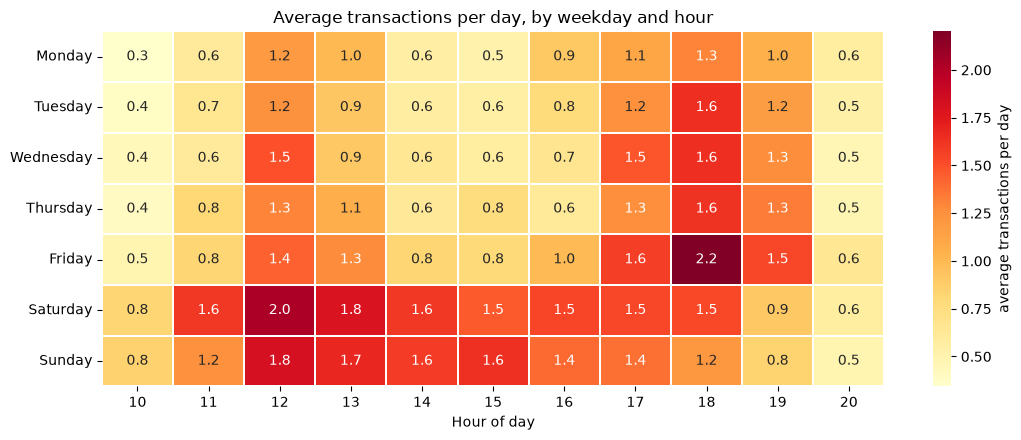

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

heat = df.groupby(["Day of week", "Hour"]).size().unstack(fill_value=0).reindex(order)
heat = heat.div(weekday_counts.reindex(order), axis=0)      # same formula for each weekday-hour cell

plt.figure(figsize=(11, 4.5))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".1f", linewidths=0.3,
            cbar_kws={"label": "average transactions per day"})
plt.title("Average transactions per day, by weekday and hour")
plt.xlabel("Hour of day")
plt.ylabel("")
plt.tight_layout()
plt.show()

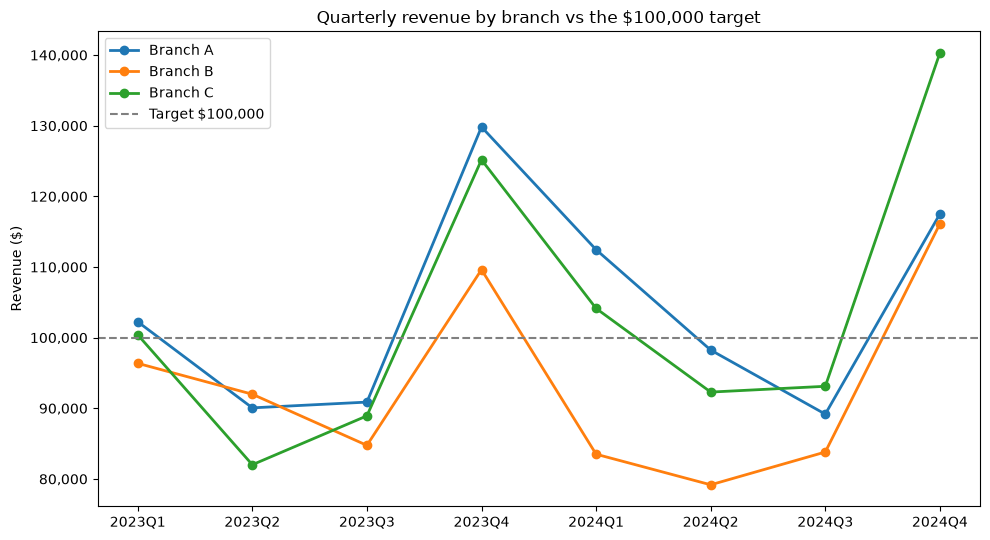

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5.5))
for branch, g in quarterly.groupby("Branch"):
    g = g.sort_values("Quarter")
    ax.plot(g["Quarter"], g["Revenue"], marker="o", linewidth=2, label=f"Branch {branch}")

ax.axhline(100_000, color="grey", linestyle="--", linewidth=1.5, label="Target $100,000")
ax.set_title("Quarterly revenue by branch vs the $100,000 target")
ax.set_ylabel("Revenue ($)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend()
plt.tight_layout()
plt.savefig("quarterly_revenue_vs_target.png", dpi=150)
plt.show()

In [23]:
df.to_csv("supermarket_sales_clean.csv", index=False)
print(f"wrote {len(df):,} clean rows x {df.shape[1]} columns to supermarket_sales_clean.csv")

wrote 8,514 clean rows x 22 columns to supermarket_sales_clean.csv


In [25]:
raw = pd.read_csv("supermarket_sales_case_study.csv")
rows_in = len(raw)

dedup = raw.drop_duplicates()
dedup_inv = dedup.drop_duplicates(subset="Invoice ID", keep="last")
conflicts_resolved = len(dedup) - len(dedup_inv)
neg_fixed = (dedup_inv["Quantity"] < 0).sum()

best = summary["avg_quarterly_revenue"].idxmax()
worst = summary["avg_quarterly_revenue"].idxmin()
city = df.groupby("Branch")["City"].first()
pct = summary["avg_quarterly_revenue"] / 100_000 * 100

lines = [
    ("Rows loaded:", f"{rows_in:,}"),
    ("Rows after cleaning:", f"{len(df):,} ({len(df)/rows_in*100:.1f}% kept)"),
    ("Trustworthy total revenue:", f"${df['Total'].sum():,.2f}  ({df['Date'].min().date()} to {df['Date'].max().date()})"),
    ("Best branch (avg quarter):", f"{city[best]} at {pct[best]:.1f}% of target, hit {summary.loc[best, 'quarters_hit']}/8 quarters"),
    ("Weakest branch:", f"{city[worst]} at {pct[worst]:.1f}% of target, hit {summary.loc[worst, 'quarters_hit']}/8 quarters"),
    ("Busiest day of week:", avg_per_day.idxmax()),
    ("Busiest time of day:", bucket_table["transactions_per_hour"].idxmax().split(" (")[0] + " (per trading hour)"),
    ("Total/tax errors fixed:", wrong.sum()),
    ("Negative quantities fixed:", neg_fixed),
    ("Conflicting records resolved:", conflicts_resolved),
]
for label, value in lines:
    print(f"{label:<31}{value}")

Rows loaded:                   8,631
Rows after cleaning:           8,514 (98.6% kept)
Trustworthy total revenue:     $2,402,106.64  (2023-01-01 to 2024-12-31)
Best branch (avg quarter):     Yangon at 103.8% of target, hit 4/8 quarters
Weakest branch:                Mandalay at 93.2% of target, hit 2/8 quarters
Busiest day of week:           Saturday
Busiest time of day:           Evening (per trading hour)
Total/tax errors fixed:        62
Negative quantities fixed:     57
Conflicting records resolved:  25
